# 06 Bayesian decision theory: should a buyer stock up on palm oil now?

This notebook covers the BUS173 topic on decision making under uncertainty. It sets up one concrete business problem and solves it the textbook way: states of nature, prior probabilities, a signal, Bayes' rule, a payoff table, expected monetary value (EMV), and the value of information.

**The buyer.** Think of the Trading Corporation of Bangladesh (TCB), which sells palm and soybean oil at subsidised prices through open-market sales, or a supermarket chain with its own warehouse. At the end of each month the buyer needs 1,000 litres of palm oil for each of the next three months. There are two actions:

- **A1, forward buy:** buy all 3,000 L now at this month's price and store them. Money is tied up (financing cost) and some oil is lost or must be stored and insured (storage and loss cost).
- **A2, buy monthly:** buy 1,000 L at the start of each month at whatever the price is then.

**States of nature.** Next month either has a price spike or it does not. A spike is the definition from notebook 03: the month-on-month log change of the national palm oil price is above the item's own 90th percentile. Here the 90th percentile is taken from the training years only (2007 to 2019), so the backtest does not use future data. For palm oil that gives a threshold of 4.22%. Notebook 03 uses the full 2007 to 2026 sample and gets 4.74%. The two differ on purpose: notebook 03 describes the whole history, while this notebook must not peek at the test years.

**Signal.** Palm oil is imported, so the buyer watches the world price converted to taka (World Bank palm oil price in USD per tonne times the BDT/USD rate). The signal is "the world price in taka rose more than 5% this month". A flood in the current month is tried as a second signal, since notebook 03 found that spikes are more frequent the month after a flood (pooled over four staples).

**Data and split.** National retail palm oil price (WFP, BDT per litre), May 2007 to Jul 2026; world prices and floods from `covariates_monthly` (to Dec 2025). Probabilities and the payoff table are estimated on decisions made in 2007 to 2019. The rule is then tested on decisions made from Jan 2020 to Dec 2025. Helper functions are in `src/bayes_decision.py`; tables go to `outputs/tables/bayes_*.csv` and README numbers to `outputs/tables/key_facts_bayes.csv`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from plot_utils import *
import bayes_decision as bd
set_style()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
facts = []
def fact(name, value, how):
    facts.append({"fact": name, "value": value, "how_computed": how})
    print(f"{name}: {value}")
SRC_B = (SRC_WFP + " World palm oil: World Bank Pink Sheet; BDT/USD: IMF. Lending rate: Bangladesh Bank via The Financial Express "
         "(Jun 2026). Storage/loss rate is an assumption.")

TRAIN, TEST = ("2007", "2019"), ("2020", "2025")
WORLD_X = 5.0                 # signal: world palm oil price in taka up more than 5% this month
R_LEND = 0.1186               # all-bank weighted average lending rate, Jun 2026 (Bangladesh Bank)
S_MONTH = 0.005               # storage, handling and loss, share of value per month (assumption)
raw = bd.load_data()
THR = raw.loc[TRAIN[0]:TRAIN[1], "dlog"].quantile(0.90)
df = bd.add_states(raw, THR, WORLD_X)
tr = df.loc[TRAIN[0]:TRAIN[1]].dropna(subset=["spike_next", "sig_world", "ratio_3"])
te = df.loc[TEST[0]:TEST[1]].dropna(subset=["spike_next", "sig_world", "ratio_3"])
fact("spike_threshold_train_pct", round(THR, 2), "90th percentile of palm oil m/m log change x 100, 2007-2019")
fact("n_train_decisions", len(tr), "Decision months with full data, 2007-2019")
fact("n_test_decisions", len(te), "Decision months with full data, 2020-2025")
print("latest price (BDT/L):", round(df.price.iloc[-1], 2), str(df.index[-1].date())[:7])

spike_threshold_train_pct: 4.22
n_train_decisions: 151
n_test_decisions: 72
latest price (BDT/L): 167.76 2026-07


The time line below shows the palm oil price, the spike months and the months when the signal fired. Spikes cluster in 2007 to 2008, 2010 to 2011 and 2021 to 2022, the years of world vegetable oil shocks and, in 2022, the taka depreciation.

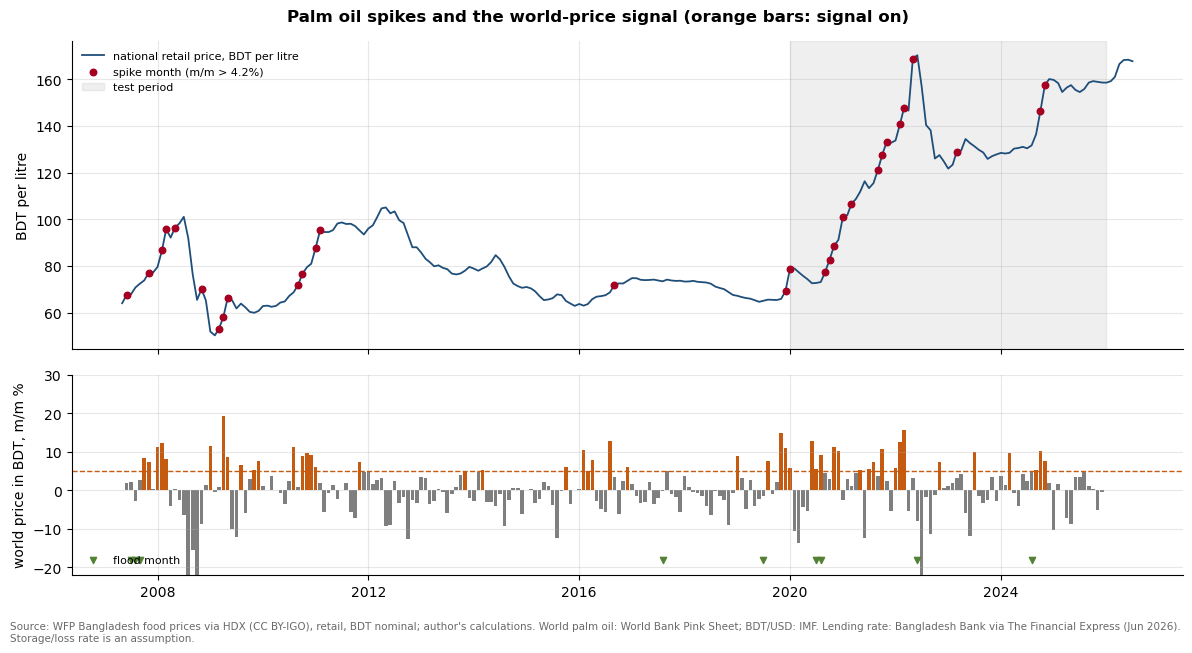

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1.3]})
ax = axes[0]
ax.plot(df.price, color=BLUE, lw=1.3, label="national retail price, BDT per litre")
sp = df.index[(df.dlog > THR)]
ax.scatter(sp, df.price.reindex(sp), color=RED, s=22, zorder=3, label=f"spike month (m/m > {THR:.1f}%)")
ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2025-12-31"), color=GREY, alpha=0.12, label="test period")
ax.set_ylabel("BDT per litre"); ax.legend(fontsize=8, loc="upper left")
ax = axes[1]
w = df.world_dlog.dropna()
ax.bar(w.index, w.values, width=25, color=np.where(w > WORLD_X, ORANGE, GREY))
ax.axhline(WORLD_X, color=ORANGE, ls="--", lw=1)
fl = df.index[df.flood]
ax.scatter(fl, np.full(len(fl), -18), marker="v", color=GREEN, s=20, label="flood month")
ax.set_ylabel("world price in BDT, m/m %"); ax.legend(fontsize=8, loc="lower left")
ax.set_ylim(-22, 30)
fig.suptitle("Palm oil spikes and the world-price signal (orange bars: signal on)", fontweight="bold")
save(fig, "fig40_palm_spikes_signal", SRC_B); plt.show()

## 1. Prior probability of a spike

The prior is the relative frequency of spikes in the training years: the share of decision months that were followed by a spike month. By construction it is close to 10%, since the threshold is the 90th percentile.

In [3]:
n_sp = int(tr.spike_next.sum()); n = len(tr)
prior = n_sp / n
fact("prior_p_spike", round(prior, 3), f"Share of 2007-2019 decision months followed by a spike ({n_sp}/{n})")

prior_p_spike: 0.099


## 2. Likelihoods and the posterior (Bayes' rule)

The likelihoods are read from the 2 x 2 table of signal against what happened next month, in the training years:

- P(signal | spike) = share of spike months that were preceded by the signal
- P(signal | no spike) = share of no-spike months that were preceded by the signal

Bayes' rule then gives

P(spike | signal) = P(signal | spike) P(spike) / [P(signal | spike) P(spike) + P(signal | no spike) P(no spike)].

The table follows the textbook layout: prior, likelihood, joint (prior x likelihood), and posterior (joint divided by the column total). The denominator, the total of the joint column, is the overall probability of seeing the signal.

In [4]:
rows = []
for sig, label in [("sig_world", f"World palm oil in BDT up > {WORLD_X:.0f}% this month"), ("sig_flood", "Flood this month"),
                   ("sig_any", "Either signal")]:
    ct = pd.crosstab(tr[sig].astype(bool), tr.spike_next.astype(bool))
    print(label); print(ct.rename(index={False: "signal off", True: "signal on"}, columns={False: "no spike", True: "spike"})); print()
    l1 = ct.loc[True, True] / ct[True].sum() if True in ct.index else 0.0
    l0 = ct.loc[True, False] / ct[False].sum() if True in ct.index else 0.0
    rows.append({"signal": sig, "label": label, "n_signal_on": int(ct.loc[True].sum()) if True in ct.index else 0,
                 "p_sig_given_spike": l1, "p_sig_given_none": l0,
                 "likelihood_ratio": l1 / l0 if l0 > 0 else np.nan,
                 "fisher_p": stats.fisher_exact(ct.values)[1] if ct.shape == (2, 2) else np.nan})
lik = pd.DataFrame(rows); lik.to_csv(TAB / "bayes_likelihoods.csv", index=False); lik.round(3)

World palm oil in BDT up > 5% this month
spike_next  no spike  spike
sig_world                  
signal off       117      5
signal on         19     10

Flood this month
spike_next  no spike  spike
sig_flood                  
signal off       131     15
signal on          5      0

Either signal
spike_next  no spike  spike
sig_any                    
signal off       112      5
signal on         24     10



,signal,label,n_signal_on,p_sig_given_spike,p_sig_given_none,likelihood_ratio,fisher_p
0,sig_world,World palm oil in BDT up > 5% this month,29,0.667,0.140,4.772,0.0
1,sig_flood,Flood this month,5,0.000,0.037,0.000,1.0
2,sig_any,Either signal,34,0.667,0.176,3.778,0.0


In [5]:
L1, L0 = lik.set_index("signal").loc["sig_world", ["p_sig_given_spike", "p_sig_given_none"]]
t_on = bd.bayes_table(prior, L1, L0, True).assign(signal="on")
t_off = bd.bayes_table(prior, L1, L0, False).assign(signal="off")
btab = pd.concat([t_on, t_off]); btab.to_csv(TAB / "bayes_prior_posterior.csv", index=False)
for t in (t_on, t_off):
    print(f"Signal {t.signal.iloc[0]}:"); print(t.drop(columns="signal").round(4).to_string(index=False))
    print(f"  total joint = P(signal {t.signal.iloc[0]}) = {t.joint.sum():.4f}"); print()
post_on, post_off = t_on.posterior.iloc[0], t_off.posterior.iloc[0]
fact("lik_sig_given_spike", round(L1, 3), "P(world price in BDT up > 5% | spike next month), 2007-2019")
fact("lik_sig_given_none", round(L0, 3), "P(world price in BDT up > 5% | no spike next month), 2007-2019")
fact("posterior_spike_signal_on", round(post_on, 3), "P(spike next month | signal on), Bayes' rule")
fact("posterior_spike_signal_off", round(post_off, 3), "P(spike next month | signal off), Bayes' rule")
fl = lik.set_index("signal").loc["sig_flood"]
fact("flood_signal_on_months_train", int(fl.n_signal_on), f"Flood months in 2007-2019 decisions; P(flood | spike) = {fl.p_sig_given_spike:.2f}")

Signal on:
           state  prior  likelihood  joint  posterior
spike next month 0.0993      0.6667 0.0662     0.3448
        no spike 0.9007      0.1397 0.1258     0.6552
  total joint = P(signal on) = 0.1921

Signal off:
           state  prior  likelihood  joint  posterior
spike next month 0.0993      0.3333 0.0331      0.041
        no spike 0.9007      0.8603 0.7748      0.959
  total joint = P(signal off) = 0.8079

lik_sig_given_spike: 0.667
lik_sig_given_none: 0.14
posterior_spike_signal_on: 0.345
posterior_spike_signal_off: 0.041
flood_signal_on_months_train: 5


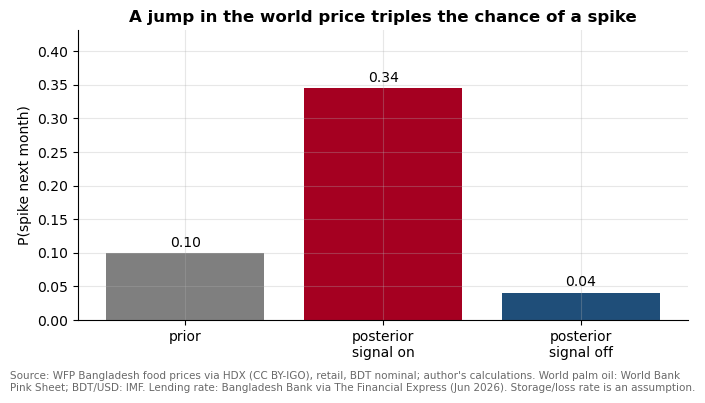

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
vals = [prior, post_on, post_off]
bars = ax.bar(["prior", "posterior\nsignal on", "posterior\nsignal off"], vals, color=[GREY, RED, BLUE])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center")
ax.set_ylabel("P(spike next month)"); ax.set_ylim(0, max(vals) * 1.25)
ax.set_title("A jump in the world price triples the chance of a spike")
save(fig, "fig41_prior_posterior", SRC_B); plt.show()

The world-price signal is informative: a spike month is several times more likely to be preceded by a jump in the world price in taka than a normal month is. Floods are not useful for palm oil. Over 2007 to 2019 no flood month was followed by a palm oil spike, so P(flood | spike) = 0, and with only a handful of flood months that zero is mostly noise. The flood effect in notebook 03 came from rice and the other staples, not from imported oil. The rest of the notebook uses the world-price signal only.

## 3. Payoff table in taka

The payoff table needs the cost of each action in each state.

**Prices after a spike or no spike.** From the training years, the average ratio of the price k months later to today's price, P(t+k)/P(t), for k = 1, 2, 3, separately for months followed by a spike and months that were not. This captures that a spike usually persists: prices do not fall back the month after.

**Carrying cost of a forward buy.** The litre used in month t+k is paid for k months early. The cost of that is k x (r/12 + s) times today's price, where

- r = 11.86% a year, the all-bank weighted average lending rate in June 2026 (Bangladesh Bank, reported by The Financial Express, "June spread remains unchanged at 5.7pc"). The policy (repo) rate was 10% from Oct 2024 and was cut to 9.5% in Aug 2026 (The Daily Star). A buyer borrows at the lending rate, not the policy rate, so the lending rate is used.
- s = 0.5% of value per month for storage, handling, insurance and loss. This is an **assumption**, not a sourced figure. Palm oil in drums keeps for months, so loss is small, but warehouse rent and handling are real costs. Section 5 varies it.

**Today's price** is the latest national retail price (Jul 2026). Costs are for the full requirement of 3 x 1,000 L.

In [7]:
growth = {"spike next month": [tr.loc[tr.spike_next == 1, f"ratio_{k}"].mean() for k in (1, 2, 3)],
          "no spike": [tr.loc[tr.spike_next == 0, f"ratio_{k}"].mean() for k in (1, 2, 3)]}
print(pd.DataFrame(growth, index=["P(t+1)/P(t)", "P(t+2)/P(t)", "P(t+3)/P(t)"]).round(4))
P0 = df.price.iloc[-1]
pay = bd.payoff_table(P0, growth, R_LEND, S_MONTH)
pay.round(0).to_csv(TAB / "bayes_payoff_table.csv")
fact("price_now_bdt_per_l", round(P0, 2), f"National retail palm oil price, {str(df.index[-1].date())[:7]}")
fact("carry_cost_pct_per_month", round(100 * bd.carry_per_month(R_LEND, S_MONTH), 2), "r/12 + s, % of price per month held")
fact("avg_3m_rise_after_spike_pct", round(100 * (growth['spike next month'][2] - 1), 1), "Mean P(t+3)/P(t) - 1 when t+1 is a spike, 2007-2019")
fact("saving_forward_if_spike_bdt", round(pay.loc['spike next month', 'saving_forward']), "Forward minus monthly cost saving, 3,000 L, spike state")
fact("saving_forward_if_no_spike_bdt", round(pay.loc['no spike', 'saving_forward']), "Same, no-spike state (negative = forward costs more)")
pay.round(0)

             spike next month  no spike
P(t+1)/P(t)            1.0776    0.9936
P(t+2)/P(t)            1.1179    0.9921
P(t+3)/P(t)            1.1162    0.9947
price_now_bdt_per_l: 167.76
carry_cost_pct_per_month: 1.49
avg_3m_rise_after_spike_pct: 11.6
saving_forward_if_spike_bdt: 37296
saving_forward_if_no_spike_bdt: -18277


,cost_forward,cost_monthly,saving_forward
state,,,
spike next month,518256.0,555552.0,37296.0
no spike,518256.0,499979.0,-18277.0


Read the table as a cost table: lower is better. If a spike comes, buying forward saves money because the buyer has locked in the old price for three months. If no spike comes, prices drift slightly down on average, and the forward buyer has paid financing and storage for nothing.

## 4. Expected monetary value, EVPI and EVSI

For a given P(spike) the expected cost of each action is the probability-weighted average of its row in the payoff table. The decision rule is to pick the action with the lower expected cost (equivalently, the higher EMV of savings).

- **Expected value of perfect information (EVPI)** is the most a buyer should pay to know the state in advance: expected cost of the best action under the prior minus the expected cost if the buyer always picked the right action for each state.
- **Expected value of sample information (EVSI)** is what the actual signal is worth: expected cost acting on the prior minus the expected cost of looking at the signal first and then acting on the posterior.
- **Efficiency of the signal** = EVSI / EVPI.

Because the payoff difference between the two actions is a straight line in P(spike), there is a single **breakeven probability**. Forward buying is the better choice whenever P(spike) is above it.

In [8]:
p_be = bd.breakeven_p(pay)
ev_prior, ev_on, ev_off = bd.emv(pay, prior), bd.emv(pay, post_on), bd.emv(pay, post_off)
emv_tab = pd.DataFrame({"P(spike)": [prior, post_on, post_off], "cost_forward": [ev_prior.forward, ev_on.forward, ev_off.forward],
                        "cost_monthly": [ev_prior.monthly, ev_on.monthly, ev_off.monthly]},
                       index=["prior (no signal)", "posterior, signal on", "posterior, signal off"])
emv_tab["best_action"] = np.where(emv_tab.cost_forward < emv_tab.cost_monthly, "forward", "monthly")
emv_tab["saving_vs_other_bdt"] = (emv_tab.cost_forward - emv_tab.cost_monthly).abs()
EVPI = bd.evpi(pay, prior)
EVSI, p_sig, _, _ = bd.evsi(pay, prior, L1, L0)
emv_tab.round(3).to_csv(TAB / "bayes_emv.csv")
pd.DataFrame([{"evpi_bdt": EVPI, "evsi_bdt": EVSI, "efficiency": EVSI / EVPI, "p_signal": p_sig, "breakeven_p": p_be,
               "evpi_bdt_per_litre": EVPI / 3000, "evsi_bdt_per_litre": EVSI / 3000}]).to_csv(TAB / "bayes_value_of_information.csv", index=False)
fact("breakeven_p_spike", round(p_be, 3), "P(spike) at which forward and monthly buying cost the same")
fact("action_prior", emv_tab.best_action.iloc[0], "Best action on the prior alone")
fact("action_signal_on", emv_tab.best_action.iloc[1], "Best action when the world-price signal is on")
fact("action_signal_off", emv_tab.best_action.iloc[2], "Best action when the signal is off")
fact("evpi_bdt", round(EVPI), "Expected value of perfect information, BDT per 3,000 L decision")
fact("evsi_bdt", round(EVSI), "Expected value of sample information (world-price signal), BDT per 3,000 L")
fact("evsi_efficiency_pct", round(100 * EVSI / EVPI, 1), "EVSI / EVPI, %")
emv_tab.round(3)

breakeven_p_spike: 0.329
action_prior: monthly
action_signal_on: forward
action_signal_off: monthly
evpi_bdt: 3705
evsi_bdt: 170
evsi_efficiency_pct: 4.6


,P(spike),cost_forward,cost_monthly,best_action,saving_vs_other_bdt
prior (no signal),0.099,518255.819,505499.587,monthly,12756.232
"posterior, signal on",0.345,518255.819,519142.059,forward,886.240
"posterior, signal off",0.041,518255.819,502256.705,monthly,15999.114


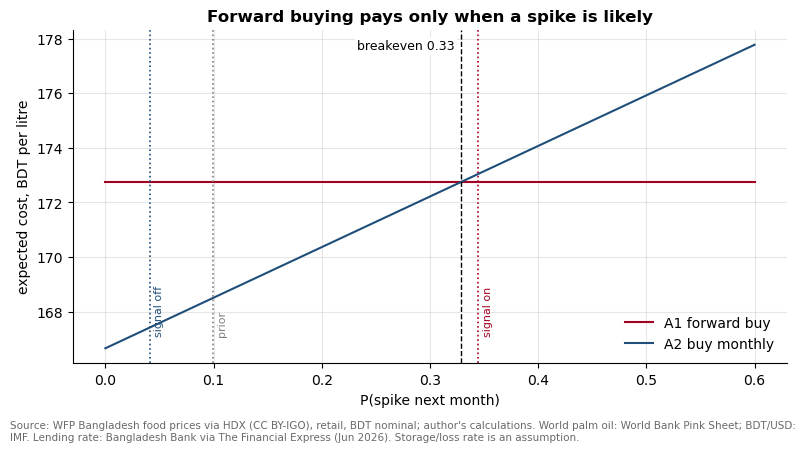

In [9]:
pp = np.linspace(0, 0.6, 121)
cf = [bd.emv(pay, p).forward / 3000 for p in pp]; cm = [bd.emv(pay, p).monthly / 3000 for p in pp]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(pp, cf, color=RED, label="A1 forward buy"); ax.plot(pp, cm, color=BLUE, label="A2 buy monthly")
ax.axvline(p_be, color="black", ls="--", lw=1)
ax.text(p_be - 0.006, 0.97, f"breakeven {p_be:.2f}", fontsize=9, ha="right", va="top", transform=ax.get_xaxis_transform(),
        bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
for p, lab, c in [(prior, "prior", GREY), (post_off, "signal off", BLUE), (post_on, "signal on", RED)]:
    ax.axvline(p, color=c, ls=":", lw=1.2); ax.text(p + 0.004, min(cm) + 0.5, lab, rotation=90, fontsize=8, color=c)
ax.set_xlabel("P(spike next month)"); ax.set_ylabel("expected cost, BDT per litre")
ax.set_title("Forward buying pays only when a spike is likely"); ax.legend(loc="lower right")
save(fig, "fig42_emv_lines", SRC_B); plt.show()

On the prior alone the buyer should buy monthly: with P(spike) = 0.10, the expected extra cost of forward buying is about BDT 12,800 per 3,000 L. When the signal is off the posterior falls to 0.04 and buying monthly is even clearer. When the signal is on the posterior is 0.345, just above the breakeven of 0.329, so the rule says forward buy, but the expected gain is only about BDT 890 per 3,000 L.

That is why EVSI is so small (about BDT 170 per decision, under 5% of EVPI). The signal changes the decision only in the months it fires, and in those months the two actions are almost tied in expected value. Perfect information is worth far more (about BDT 3,700 per decision), because a buyer who knew a spike was coming would lock in the price and save about BDT 37,000.

## 5. Out-of-sample check, 2020 to 2025

The rule is now applied month by month to decisions made from Jan 2020 to Dec 2025, with every number (threshold, likelihoods, price paths) fixed from the training years and the carrying cost held at today's rates. Each decision month is treated as its own 3-month requirement, and the realized cost uses the actual prices that followed. Three strategies are compared:

1. always buy monthly
2. always forward buy
3. the Bayes rule: forward buy when the posterior is above the breakeven probability, otherwise buy monthly

There is also an oracle that knows the future (forward buy only when it turns out cheaper). It is not achievable; it shows the most any rule could save. The decision months overlap (a decision in Jan covers Feb to Apr, one in Feb covers Mar to May), so the comparison is about the average cost per decision rather than a buyer's actual cash flow.

In [10]:
rc = bd.realized_costs(df, R_LEND, S_MONTH).loc[te.index]
post = np.where(te.sig_world.astype(bool), post_on, post_off)
rc["bayes"] = np.where(post > p_be, rc.cost_forward, rc.cost_monthly)
rc["oracle"] = rc[["cost_forward", "cost_monthly"]].min(axis=1)
rc["signal"] = te.sig_world.astype(bool); rc["spike_next"] = te.spike_next.astype(bool)
rc.to_csv(TAB / "bayes_backtest_monthly.csv")
summ = pd.DataFrame({"strategy": ["always monthly", "always forward", "Bayes rule", "oracle (perfect foresight)"],
                     "total_cost_bdt": [rc.cost_monthly.sum(), rc.cost_forward.sum(), rc.bayes.sum(), rc.oracle.sum()]})
summ["vs_monthly_bdt"] = summ.total_cost_bdt - rc.cost_monthly.sum()
summ["vs_monthly_pct"] = 100 * summ.vs_monthly_bdt / rc.cost_monthly.sum()
summ["per_decision_bdt_per_litre"] = summ.vs_monthly_bdt / len(rc) / 3000
summ.to_csv(TAB / "bayes_backtest_summary.csv", index=False)
n_fwd = int((post > p_be).sum()); hits = int(((post > p_be) & rc.spike_next).sum())
fact("test_spike_rate", round(rc.spike_next.mean(), 3), f"Share of 2020-2025 decisions followed by a spike ({int(rc.spike_next.sum())}/{len(rc)})")
fact("test_signal_months", int(rc.signal.sum()), "Months the world-price signal fired, 2020-2025")
fact("test_bayes_forward_months", n_fwd, f"Months the rule said forward buy; {hits} were followed by a spike")
for s, k in zip(summ.strategy, ["monthly", "forward", "bayes", "oracle"]):
    v = summ.set_index("strategy").loc[s]
    fact(f"test_{k}_vs_monthly_pct", round(v.vs_monthly_pct, 2), f"{s}: total realized cost vs always monthly, %, 2020-2025")
fact("test_bayes_saving_bdt_per_litre", round(-summ.set_index('strategy').loc['Bayes rule', 'per_decision_bdt_per_litre'], 2),
     "Bayes rule average saving vs always monthly, BDT per litre")
summ.round(2)

test_spike_rate: 0.194
test_signal_months: 19
test_bayes_forward_months: 19
test_monthly_vs_monthly_pct: 0.0
test_forward_vs_monthly_pct: 1.19
test_bayes_vs_monthly_pct: -0.72
test_oracle_vs_monthly_pct: -1.75
test_bayes_saving_bdt_per_litre: 0.92


,strategy,total_cost_bdt,vs_monthly_bdt,vs_monthly_pct,per_decision_bdt_per_litre
0,always monthly,27854227.07,0.00,0.00,0.00
1,always forward,28185715.53,331488.46,1.19,1.53
2,Bayes rule,27654965.79,-199261.28,-0.72,-0.92
3,oracle (perfect foresight),27366002.42,-488224.65,-1.75,-2.26


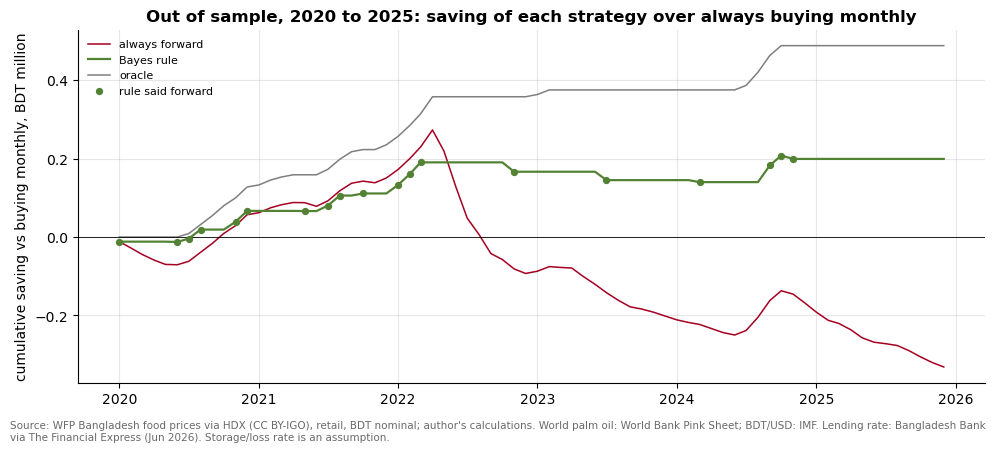

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
base = rc.cost_monthly
for col, lab, c in [("cost_forward", "always forward", RED), ("bayes", "Bayes rule", GREEN), ("oracle", "oracle", GREY)]:
    ax.plot(((base - rc[col]).cumsum()) / 1e6, label=lab, color=c, lw=1.6 if col == "bayes" else 1.1)
ax.axhline(0, color="black", lw=0.6)
on = rc.index[(post > p_be)]
ax.scatter(on, ((base - rc.bayes).cumsum() / 1e6).reindex(on), color=GREEN, s=18, zorder=3, label="rule said forward")
ax.set_ylabel("cumulative saving vs buying monthly, BDT million"); ax.legend(fontsize=8)
ax.set_title("Out of sample, 2020 to 2025: saving of each strategy over always buying monthly")
save(fig, "fig43_backtest_cumulative", SRC_B); plt.show()

**Variant at the capped lending rate.** Bangladesh Bank capped bank lending rates at 9% from 1 April 2020 (BRPD Circular No. 03, 24 February 2020). The monetary policy for July to December 2023, announced on 18 June 2023, replaced the cap with the SMART reference rate from 1 July 2023. The main backtest charges 11.86% throughout. Here decisions made from April 2020 to June 2023 are charged 9% instead, and the breakeven probability for those months is recomputed at 9%. Everything else stays the same. The cap was a ceiling, so 9% is still on the high side for those years.

In [12]:
R_CAP = 0.09
r_path = pd.Series(R_LEND, index=df.index)
r_path.loc["2020-04":"2023-06"] = R_CAP
rc9 = bd.realized_costs(df, r_path, S_MONTH).loc[te.index]
p_be9 = pd.Series([bd.breakeven_p(bd.payoff_table(P0, growth, r, S_MONTH)) for r in r_path.loc[te.index]], index=te.index)
fwd9 = post > p_be9
rc9["bayes"] = np.where(fwd9, rc9.cost_forward, rc9.cost_monthly)
rc9["oracle"] = rc9[["cost_forward", "cost_monthly"]].min(axis=1)
summ9 = pd.DataFrame({"strategy": ["always monthly", "always forward", "Bayes rule", "oracle (perfect foresight)"],
                      "total_cost_bdt": [rc9.cost_monthly.sum(), rc9.cost_forward.sum(), rc9.bayes.sum(), rc9.oracle.sum()]})
summ9["vs_monthly_pct"] = 100 * (summ9.total_cost_bdt / rc9.cost_monthly.sum() - 1)
summ9["per_decision_bdt_per_litre"] = (summ9.total_cost_bdt - rc9.cost_monthly.sum()) / len(rc9) / 3000
summ9.to_csv(TAB / "bayes_backtest_summary_rate_cap.csv", index=False)
fact("breakeven_p_at_9pct", round(bd.breakeven_p(bd.payoff_table(P0, growth, R_CAP, S_MONTH)), 3), "Breakeven P(spike) at a 9% lending rate")
fact("test_cap_bayes_forward_months", int(fwd9.sum()), "Months the rule said forward buy with 9% charged Apr 2020-Jun 2023")
for s, k in zip(summ9.strategy, ["monthly", "forward", "bayes", "oracle"]):
    fact(f"test_cap_{k}_vs_monthly_pct", round(summ9.set_index("strategy").loc[s, "vs_monthly_pct"], 2),
         f"{s}: realized cost vs always monthly, %, 9% rate Apr 2020-Jun 2023, 11.86% otherwise")
summ9.round(3)

breakeven_p_at_9pct: 0.286
test_cap_bayes_forward_months: 19
test_cap_monthly_vs_monthly_pct: 0.0
test_cap_forward_vs_monthly_pct: 0.95
test_cap_bayes_vs_monthly_pct: -0.79
test_cap_oracle_vs_monthly_pct: -1.88


,strategy,total_cost_bdt,vs_monthly_pct,per_decision_bdt_per_litre
0,always monthly,2.785423e+07,0.000,0.000
1,always forward,2.812007e+07,0.954,1.231
2,Bayes rule,2.763471e+07,-0.788,-1.016
3,oracle (perfect foresight),2.733110e+07,-1.878,-2.422


At 9% the breakeven probability falls from 0.329 to 0.286. The posterior is 0.345 when the signal is on and 0.041 when it is off, so it sits on the same side of the breakeven at both rates. The rule makes the same 19 forward buys. Only the cost of carrying the oil changes:

- always forward buy: 0.95% more expensive than always monthly (1.19% at 11.86% throughout)
- Bayes rule: 0.79% cheaper (0.72%)
- oracle: 1.88% cheaper (1.75%)

The cap makes forward buying a little more attractive, but it does not change any decision or the main conclusion.

In 2020 to 2025 the spike rate was 19% (14 of 72 decision months), almost twice the training rate, because of the 2021 to 2022 world price surge and the 2022 to 2023 taka depreciation. The signal fired in 19 months; 8 of them were followed by a spike, a hit rate of 42%, close to the 34% the posterior promised.

Total realized cost over the 72 decisions, compared with always buying monthly:

- always forward buy: 1.2% more expensive (the carrying cost outweighs the spikes it catches)
- Bayes rule: 0.7% cheaper, about BDT 0.9 per litre
- oracle with perfect foresight: 1.75% cheaper

So out of sample the rule captured about 40% of what perfect foresight could have saved. The gain is real but small, and it rests on 19 forward-buy months. One or two more false alarms would wipe out much of it. Section 6 shows the same thing from another angle: the decision sits close to the breakeven line.

## 6. Sensitivity: when does the decision flip?

The breakeven probability depends on the carrying cost and on how big a spike is. Three checks:

- financing rate from 6% to 18% a year, for storage-and-loss rates of 0.25%, 0.5% and 1% a month
- the size of the spike: scale the average post-spike price rise by 0.5 to 1.5
- the signal threshold X: 3%, 5% or 7%

The posterior with the signal on is drawn as a flat line. Where it lies above the breakeven curve, the rule says forward buy when the signal fires.

At 0.5% a month storage, forward buying on the signal stops paying once the lending rate passes about 13%, only a little above the June 2026 rate. At 1% a month storage it does not pay at any rate of 8% or more. The signal threshold matters too. At X = 3% the signal fires more often, but the posterior (0.24) stays below the breakeven, so the rule never forward buys and EVSI is zero. At X = 7% the posterior is higher (0.43) and EVSI rises to about BDT 770, but the signal fired in only 13 test months and saved 0.4%.

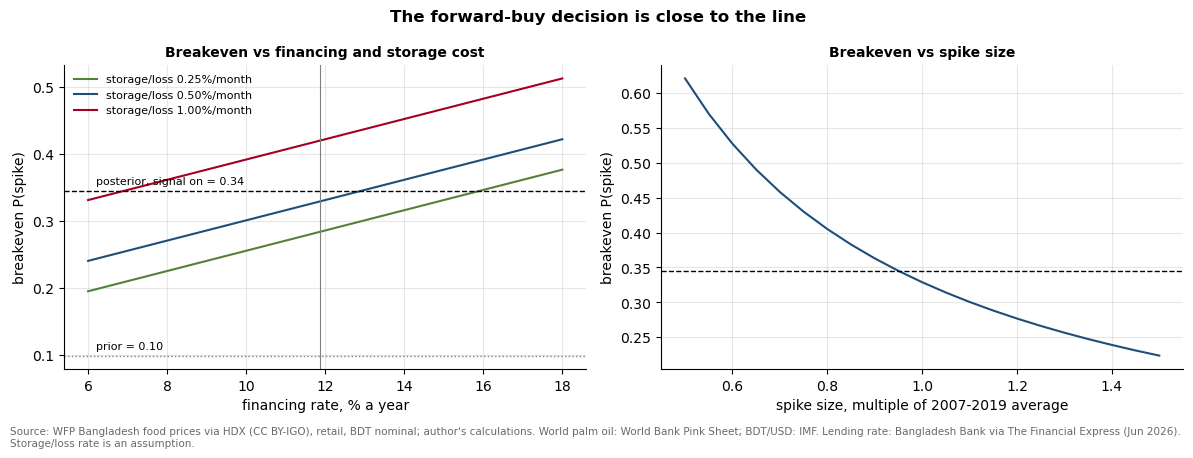

lending_rate_where_decision_flips_pct: 13.0


storage_loss_per_month,0.0025,0.0050,0.0100
lending_rate,,,
0.0600,True,True,True
0.0800,True,True,False
0.1000,True,True,False
0.1186,True,True,False
0.1400,True,False,False
0.1600,False,False,False
0.1800,False,False,False


In [13]:
rates = np.linspace(0.06, 0.18, 25)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
for s, c in [(0.0025, GREEN), (0.005, BLUE), (0.01, RED)]:
    ax.plot(100 * rates, [bd.breakeven_p(bd.payoff_table(P0, growth, r, s)) for r in rates], color=c, label=f"storage/loss {100*s:.2f}%/month")
ax.axhline(post_on, color="black", ls="--", lw=1); ax.text(6.2, post_on + 0.01, f"posterior, signal on = {post_on:.2f}", fontsize=8)
ax.axhline(prior, color=GREY, ls=":", lw=1); ax.text(6.2, prior + 0.01, f"prior = {prior:.2f}", fontsize=8)
ax.axvline(100 * R_LEND, color=GREY, lw=0.8); ax.set_xlabel("financing rate, % a year"); ax.set_ylabel("breakeven P(spike)")
ax.set_title("Breakeven vs financing and storage cost", fontsize=10); ax.legend(fontsize=8)
ax = axes[1]
mults = np.linspace(0.5, 1.5, 21); rows = []
for m in mults:
    g = {"spike next month": [1 + m * (x - 1) for x in growth["spike next month"]], "no spike": growth["no spike"]}
    rows.append(bd.breakeven_p(bd.payoff_table(P0, g, R_LEND, S_MONTH)))
ax.plot(mults, rows, color=BLUE); ax.axhline(post_on, color="black", ls="--", lw=1)
ax.set_xlabel("spike size, multiple of 2007-2019 average"); ax.set_ylabel("breakeven P(spike)")
ax.set_title("Breakeven vs spike size", fontsize=10)
fig.suptitle("The forward-buy decision is close to the line", fontweight="bold")
save(fig, "fig44_sensitivity_breakeven", SRC_B); plt.show()
sens = []
for r in [0.06, 0.08, 0.10, 0.1186, 0.14, 0.16, 0.18]:
    for s in [0.0025, 0.005, 0.01]:
        pb = bd.breakeven_p(bd.payoff_table(P0, growth, r, s))
        sens.append({"lending_rate": r, "storage_loss_per_month": s, "breakeven_p": pb, "forward_if_signal_on": post_on > pb})
sens = pd.DataFrame(sens); sens.to_csv(TAB / "bayes_sensitivity_rates.csv", index=False)
r_flip = rates[np.argmin(np.abs(np.array([bd.breakeven_p(bd.payoff_table(P0, growth, r, S_MONTH)) for r in rates]) - post_on))]
fact("lending_rate_where_decision_flips_pct", round(100 * r_flip, 1), "Financing rate at which breakeven = posterior with signal on (storage 0.5%/month)")
sens.pivot(index="lending_rate", columns="storage_loss_per_month", values="forward_if_signal_on")

In [14]:
rows = []
for X in [3.0, 5.0, 7.0]:
    d = bd.add_states(raw, THR, X)
    a = d.loc[TRAIN[0]:TRAIN[1]].dropna(subset=["spike_next", "sig_world", "ratio_3"])
    b = d.loc[TEST[0]:TEST[1]].dropna(subset=["spike_next", "sig_world", "ratio_3"])
    l1 = a.loc[a.spike_next == 1, "sig_world"].mean(); l0 = a.loc[a.spike_next == 0, "sig_world"].mean()
    po = bd.bayes_table(prior, l1, l0, True).posterior.iloc[0]
    pf = bd.bayes_table(prior, l1, l0, False).posterior.iloc[0]
    ev = bd.evsi(pay, prior, l1, l0)[0]
    rcb = bd.realized_costs(d, R_LEND, S_MONTH).loc[b.index]
    pst = np.where(b.sig_world.astype(bool), po, pf)
    cost = np.where(pst > p_be, rcb.cost_forward, rcb.cost_monthly).sum()
    rows.append({"X_pct": X, "p_sig_given_spike": l1, "p_sig_given_none": l0, "posterior_on": po, "evsi_bdt": ev,
                 "test_signal_months": int(b.sig_world.sum()), "test_vs_monthly_pct": 100 * (cost / rcb.cost_monthly.sum() - 1)})
xs = pd.DataFrame(rows); xs.to_csv(TAB / "bayes_sensitivity_signal.csv", index=False); xs.round(3)

,X_pct,p_sig_given_spike,p_sig_given_none,posterior_on,evsi_bdt,test_signal_months,test_vs_monthly_pct
0,3.0,0.667,0.228,0.244,0.000,32,0.000
1,5.0,0.667,0.140,0.345,170.205,19,-0.715
2,7.0,0.600,0.088,0.429,770.476,13,-0.446


## 7. A second Bayesian example: Beta-binomial updating of the spike rate

Sections 1 to 6 treat the prior P(spike) as a fixed number. A Bayesian would instead treat the spike rate θ as uncertain and update it as data arrive. With a Beta(a, b) prior and k spikes in n months, the posterior is Beta(a + k, b + n - k). This is the conjugate update, and the 95% credible interval comes straight from the Beta quantiles.

Start from a flat Beta(1, 1) prior (every rate between 0 and 1 equally likely), update with 2007 to 2019, then update again with 2020 to 2025. Months are not independent (spikes come in runs), so the intervals are narrower than they should be; treat them as a teaching example.

beta_post_mean_train: 0.105
beta_post_mean_all: 0.133


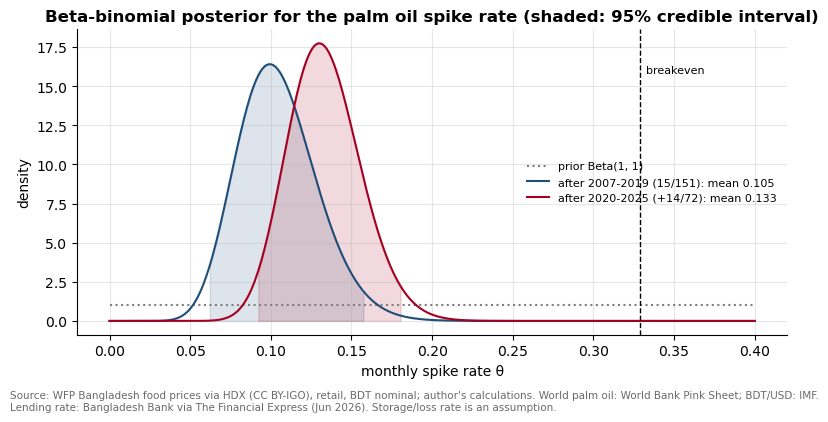

,stage,a,b,mean,lo,hi
0,"prior Beta(1,1)",1,1,0.5000,0.0250,0.9750
1,after 2007-2019 (15/151),16,137,0.1046,0.0614,0.1575
2,after 2020-2025 (+14/72),30,195,0.1333,0.0922,0.1806


In [15]:
k1, n1 = int(tr.spike_next.sum()), len(tr)
k2, n2 = int(te.spike_next.sum()), len(te)
b1 = bd.beta_posterior(1, 1, k1, n1); b2 = bd.beta_posterior(b1["a"], b1["b"], k2, n2)
bt = pd.DataFrame([{"stage": "prior Beta(1,1)", "a": 1, "b": 1, "mean": 0.5, "lo": 0.025, "hi": 0.975},
                   {"stage": f"after 2007-2019 ({k1}/{n1})", **b1}, {"stage": f"after 2020-2025 (+{k2}/{n2})", **b2}])
bt.to_csv(TAB / "bayes_beta_binomial.csv", index=False)
fact("beta_post_mean_train", round(b1["mean"], 3), f"Posterior mean spike rate after 2007-2019, 95% CrI {b1['lo']:.3f} to {b1['hi']:.3f}")
fact("beta_post_mean_all", round(b2["mean"], 3), f"Posterior mean after adding 2020-2025, 95% CrI {b2['lo']:.3f} to {b2['hi']:.3f}")
th = np.linspace(0, 0.4, 400)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(th, stats.beta.pdf(th, 1, 1), color=GREY, ls=":", label="prior Beta(1, 1)")
for bb, c, lab in [(b1, BLUE, bt.stage[1]), (b2, RED, bt.stage[2])]:
    ax.plot(th, stats.beta.pdf(th, bb["a"], bb["b"]), color=c, label=f"{lab}: mean {bb['mean']:.3f}")
    ax.fill_between(th, 0, stats.beta.pdf(th, bb["a"], bb["b"]), where=(th >= bb["lo"]) & (th <= bb["hi"]), color=c, alpha=0.15)
ax.axvline(p_be, color="black", ls="--", lw=1); ax.text(p_be + 0.004, ax.get_ylim()[1] * 0.85, "breakeven", fontsize=8)
ax.set_xlabel("monthly spike rate θ"); ax.set_ylabel("density"); ax.legend(fontsize=8)
ax.set_title("Beta-binomial posterior for the palm oil spike rate (shaded: 95% credible interval)")
save(fig, "fig45_beta_binomial", SRC_B); plt.show()
bt.round(4)

Even after the busy 2020 to 2025 period, the credible interval for the unconditional spike rate stays well below the breakeven probability. Without a signal, a buyer should not forward buy palm oil three months at a time at current Bangladeshi lending rates.

## Key facts

In [16]:
kf = pd.DataFrame(facts); kf.to_csv(TAB / "key_facts_bayes.csv", index=False); kf

,fact,value,how_computed
0,spike_threshold_train_pct,4.22,90th percentile of palm oil m/m log change x 1...
1,n_train_decisions,151,"Decision months with full data, 2007-2019"
2,n_test_decisions,72,"Decision months with full data, 2020-2025"
3,prior_p_spike,0.099,Share of 2007-2019 decision months followed by...
4,lik_sig_given_spike,0.667,P(world price in BDT up > 5% | spike next mont...
5,lik_sig_given_none,0.14,P(world price in BDT up > 5% | no spike next m...
6,posterior_spike_signal_on,0.345,"P(spike next month | signal on), Bayes' rule"
7,posterior_spike_signal_off,0.041,"P(spike next month | signal off), Bayes' rule"
8,flood_signal_on_months_train,5,Flood months in 2007-2019 decisions; P(flood |...
9,price_now_bdt_per_l,167.76,"National retail palm oil price, 2026-07"


## Limits

- The state is defined by next month only, but the payoff covers three months. The payoff table handles this by using the average price path after a spike or no spike, which averages over what happens in months two and three.
- The main backtest applies one financing rate (Jun 2026) to all years. Lending rates were capped at 9% from April 2020 to June 2023. The variant in section 5 charges 9% in those months; no decision changes and the Bayes rule saving moves from 0.72% to 0.79%.
- Gaps of up to three months in the price series are filled by interpolation, which uses the price after the gap. For the backtest that is a mild look-ahead, on a handful of months.
- The storage and loss rate of 0.5% a month is an assumption. Section 6 shows how much it matters.
- Only 15 spikes in the training years, and fewer signal months. Likelihoods estimated from counts this small carry wide error bands; the Fisher test p-value in section 2 gives a sense of it.
- Real buyers like TCB face budget limits, tender lead times and storage capacity. None of that is in the model, which is meant to show the method, not to set procurement policy.

**Sources for rates.** Weighted average lending rate 11.86% (June 2026): The Financial Express, "June spread remains unchanged at 5.7pc", https://thefinancialexpress.com.bd/bangladesh/june-spread-remains-unchanged-at-57pc. Policy rate cut from 10% to 9.5% in Aug 2026: The Daily Star, https://www.thedailystar.net/business/banking/news/bb-cuts-policy-rate-95-after-2-years-4236481. 9% lending-rate cap from 1 April 2020: Bangladesh Bank, BRPD Circular No. 03 (24 February 2020), listed at https://www.bb.org.bd/en/index.php/mediaroom/circular; reported by The Business Standard, https://www.tbsnews.net/node/297970. Cap replaced by the SMART reference rate from 1 July 2023: Bangladesh Bank monetary policy for July-December 2023, announced 18 June 2023, https://www.bb.org.bd/en/index.php/monetaryactivity/mps; reported by Prothom Alo, "Bangladesh Bank lifts interest cap to control inflation", https://en.prothomalo.com/business/local/mlhvuwarpr.